In [1]:
# =====================================================
# APPLICATION 1: OTP VERIFICATION SYSTEM
# FINITE AUTOMATA IMPLEMENTATION
# =====================================================

# STEP 1: Define DFA components

# Input Alphabet
alphabet = "0123456789"

# Set of States
states = ['q0', 'q1', 'q2', 'q3',
          'q4', 'q5', 'q6', 'qd']

# Initial State
initial_state = 'q0'

# Final State
final_states = ['q6']


# STEP 2: Define the Transition Function

def transition(state, symbol):

    if state == 'qd':
        return 'qd'

    if symbol not in alphabet:
        return 'qd'

    if state == 'q6':
        return 'qd'

    next_number = int(state[1]) + 1

    return 'q' + str(next_number)


# STEP 3: Implement DFA Processing

def otp_dfa(otp):

    current_state = initial_state

    print("\nInput OTP:", otp)
    print("Initial State:", current_state)

    for symbol in otp:

        next_state = transition(current_state, symbol)

        print("Input Symbol:", symbol,
              "| Current State:", current_state,
              "| Next State:", next_state)

        current_state = next_state

    # STEP 4: Check Final State

    if current_state in final_states:
        print("Final State:", current_state)
        print("Result: ACCEPTED")
        return "Accepted"

    else:
        print("Final State:", current_state)
        print("Result: REJECTED")
        return "Rejected"


# STEP 5: Test Multiple Inputs

test_cases = [
    "583920",
    "72941",
    "8461937",
    "105827",
    "12A456"
]

print("OTP VERIFICATION - TEST RESULTS")
print("=" * 45)

for otp in test_cases:
    otp_dfa(otp)
    print("-" * 45)


# STEP 6: Accept Input From User

user_otp = input("\nEnter your 6-digit OTP: ")

otp_dfa(user_otp)

OTP VERIFICATION - TEST RESULTS

Input OTP: 583920
Initial State: q0
Input Symbol: 5 | Current State: q0 | Next State: q1
Input Symbol: 8 | Current State: q1 | Next State: q2
Input Symbol: 3 | Current State: q2 | Next State: q3
Input Symbol: 9 | Current State: q3 | Next State: q4
Input Symbol: 2 | Current State: q4 | Next State: q5
Input Symbol: 0 | Current State: q5 | Next State: q6
Final State: q6
Result: ACCEPTED
---------------------------------------------

Input OTP: 72941
Initial State: q0
Input Symbol: 7 | Current State: q0 | Next State: q1
Input Symbol: 2 | Current State: q1 | Next State: q2
Input Symbol: 9 | Current State: q2 | Next State: q3
Input Symbol: 4 | Current State: q3 | Next State: q4
Input Symbol: 1 | Current State: q4 | Next State: q5
Final State: q5
Result: REJECTED
---------------------------------------------

Input OTP: 8461937
Initial State: q0
Input Symbol: 8 | Current State: q0 | Next State: q1
Input Symbol: 4 | Current State: q1 | Next State: q2
Input Symb

'Accepted'

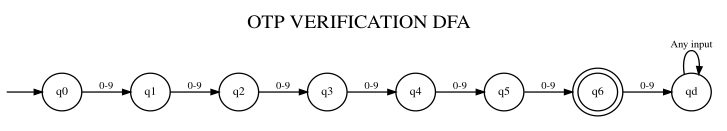

In [2]:
# =====================================================
# OTP VERIFICATION - DFA STATE DIAGRAM
# =====================================================

from graphviz import Digraph

dot = Digraph('OTP_DFA')

# Compact diagram settings
dot.attr(
    rankdir='LR',
    size='10,2.5!',
    ratio='compress',
    nodesep='0.25',
    ranksep='0.35',
    margin='0.1',
    label='OTP VERIFICATION DFA',
    labelloc='t',
    fontsize='15'
)

dot.attr(
    'node',
    shape='circle',
    width='0.42',
    height='0.42',
    fixedsize='true',
    fontsize='9'
)

dot.attr(
    'edge',
    fontsize='8',
    arrowsize='0.6'
)

# STEP 1: Create DFA states

dot.node('start', label='', shape='none', width='0')

for state in ['q0', 'q1', 'q2', 'q3',
              'q4', 'q5', 'q6', 'qd']:

    if state == 'q6':
        dot.node(state, shape='doublecircle')
    else:
        dot.node(state)

# STEP 2: Set initial state

dot.edge('start', 'q0')

# STEP 3: Add valid transitions

for i in range(6):
    dot.edge('q' + str(i),
             'q' + str(i+1),
             label='0-9')

# STEP 4: Add dead state transitions

dot.edge('q6', 'qd', label='0-9')
dot.edge('qd', 'qd', label='Any input')

# STEP 5: Display diagram

dot